<a href="https://colab.research.google.com/github/sidcodes2727/ML-labs/blob/main/MLLab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import kagglehub
path = kagglehub.dataset_download("uciml/mushroom-classification")
print(path)

Using Colab cache for faster access to the 'mushroom-classification' dataset.
/kaggle/input/mushroom-classification


In [ ]:
df = pd.read_csv('/kaggle/input/mushroom-classification/mushrooms.csv')

print(df.shape)
print(df.columns)
df.head()

(8124, 23)
Index(['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='object')


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
print("Duplicate values:", df.duplicated().sum())
print()

print("Missing values:")
print(df.isnull().sum())

Duplicate values: 0

Missing values:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


In [ ]:
for c in df.columns:
    print(c)
    print(df[c].unique())
    print()

class
['p' 'e']

cap-shape
['x' 'b' 's' 'f' 'k' 'c']

cap-surface
['s' 'y' 'f' 'g']

cap-color
['n' 'y' 'w' 'g' 'e' 'p' 'b' 'u' 'c' 'r']

bruises
['t' 'f']

odor
['p' 'a' 'l' 'n' 'f' 'c' 'y' 's' 'm']

gill-attachment
['f' 'a']

gill-spacing
['c' 'w']

gill-size
['n' 'b']

gill-color
['k' 'n' 'g' 'p' 'w' 'h' 'u' 'e' 'b' 'r' 'y' 'o']

stalk-shape
['e' 't']

stalk-root
['e' 'c' 'b' 'r' '?']

stalk-surface-above-ring
['s' 'f' 'k' 'y']

stalk-surface-below-ring
['s' 'f' 'y' 'k']

stalk-color-above-ring
['w' 'g' 'p' 'n' 'b' 'e' 'o' 'c' 'y']

stalk-color-below-ring
['w' 'p' 'g' 'b' 'n' 'e' 'y' 'o' 'c']

veil-type
['p']

veil-color
['w' 'n' 'o' 'y']

ring-number
['o' 't' 'n']

ring-type
['p' 'e' 'l' 'f' 'n']

spore-print-color
['k' 'n' 'u' 'h' 'w' 'r' 'o' 'y' 'b']

population
['s' 'n' 'a' 'v' 'y' 'c']

habitat
['u' 'g' 'm' 'd' 'p' 'w' 'l']



In [ ]:
print(df["class"].value_counts())

class
e    4208
p    3916
Name: count, dtype: int64


In [ ]:
print(df["stalk-root"].unique())

print("Mode:")
print(df["stalk-root"].mode())

['e' 'c' 'b' 'r' '?']
Mode:
0    b
Name: stalk-root, dtype: object


In [ ]:
req = df["stalk-root"].mode()[0]
df["stalk-root"] = df["stalk-root"].replace("?", req)
print(df["stalk-root"].unique())

['e' 'c' 'b' 'r']


In [ ]:
from sklearn.preprocessing import OneHotEncoder
columns = df.drop(columns=['class']).columns.tolist()

for col in columns:
    enc= OneHotEncoder()
    encoded= enc.fit_transform(df[[col]]).toarray()
    enc_df= pd.DataFrame(encoded,columns=[col+str(i) for i in range(encoded.shape[1])])
    df= df.drop(columns=[col])
    df= df.join(enc_df)

df

,class,cap-shape0,cap-shape1,cap-shape2,cap-shape3,cap-shape4,cap-shape5,cap-surface0,cap-surface1,cap-surface2,...,population3,population4,population5,habitat0,habitat1,habitat2,habitat3,habitat4,habitat5,habitat6
0,p,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,e,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,e,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,p,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,e,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8120,e,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8121,e,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8122,p,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
print(df.shape)
df.head()

(8124, 117)


,class,cap-shape0,cap-shape1,cap-shape2,cap-shape3,cap-shape4,cap-shape5,cap-surface0,cap-surface1,cap-surface2,...,population3,population4,population5,habitat0,habitat1,habitat2,habitat3,habitat4,habitat5,habitat6
0,p,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,e,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,e,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,p,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,e,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
df['class'] = df['class'].map({'e':0,'p':1})
df.head()

,class,cap-shape0,cap-shape1,cap-shape2,cap-shape3,cap-shape4,cap-shape5,cap-surface0,cap-surface1,cap-surface2,...,population3,population4,population5,habitat0,habitat1,habitat2,habitat3,habitat4,habitat5,habitat6
0,1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
X = df.drop(columns=["class"])
y = df["class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (8124, 116)
y shape: (8124,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.3,random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5686, 116)
X_test: (2438, 116)
y_train: (5686,)
y_test: (2438,)


In [ ]:
X_train=X_train.values
X_test= X_test.values

y_train= y_train.values
y_test= y_test.values

In [ ]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [ ]:
def logistic_regression(X,y,lr=0.01,epochs=1000):
    m,n=X.shape
    w= np.zeros(n)
    b= 0
    errors = []

    for i in range(epochs):
        z=np.dot(X, w) + b
        p=sigmoid(z)
        error= -np.mean(y*np.log(p)+(1-y)*np.log(1-p))

        errors.append(error)
        dw= (1/m)*np.dot(X.T, (p-y))

        db= (1/m)*np.sum(p-y)
        w= w- lr*dw
        b= b- lr*db

    return w,b,errors

In [ ]:
weights,bias,errors= logistic_regression(X_train,y_train,lr=0.01,epochs=5000)

print("Weights:")
print(weights)

print("\nBias:")
print(bias)

Weights:
[-0.07611048  0.01987526  0.06863729  0.0038314  -0.05968219  0.04111294
 -0.39026018  0.01449036  0.38105439 -0.00762035  0.22158225 -0.05271857
  0.00466549 -0.05423489 -0.19385526  0.19356502 -0.06225912 -0.07865006
  0.11083879 -0.09126943  0.25233457 -0.25467036 -0.38285585  0.42495302
  1.07771557 -0.36340533  0.09528741 -1.80637896  0.54230701  0.20802924
  0.20201211 -0.12250516  0.12016938  0.59905721 -0.601393   -0.95956506
  0.95722928  0.56272204 -0.08830569  0.1266718   0.13407535 -0.09262913
 -0.29648623 -0.055374   -0.0334386   0.10670377 -0.13780366 -0.2385759
  0.01010446  0.19588846 -0.19822425  0.40697729 -0.2737903   0.03067931
 -0.16620208 -0.07126207  0.60209299 -0.54952427  0.01635757 -0.22515612
  0.4833885  -0.24372905 -0.01683912  0.14146117  0.09528741 -0.08540456
 -0.22461444  0.12123469 -0.17413379  0.13245971 -0.04737371  0.03874773
  0.14396881  0.09528741 -0.08481255 -0.22002014 -0.00652475 -0.17413379
  0.14631578  0.04035697  0.05722648 -0.002

In [ ]:
def predict(X, weights, bias):
    z= np.dot(X, weights) + bias
    p= sigmoid(z)
    predictions= []

    for prob in p:
        if prob>=0.5:
            predictions.append(1)
        else:
            predictions.append(0)

    return np.array(predictions)

In [ ]:
y_pred= predict(X_test,weights,bias)

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

z= np.dot(X_test,weights) + bias
y_prob= sigmoid(z)

fpr,tpr,thresholds= roc_curve(y_test,y_prob)
auc_score= roc_auc_score(y_test,y_prob)
print("AUC:",auc_score)

AUC: 0.9979380498842384


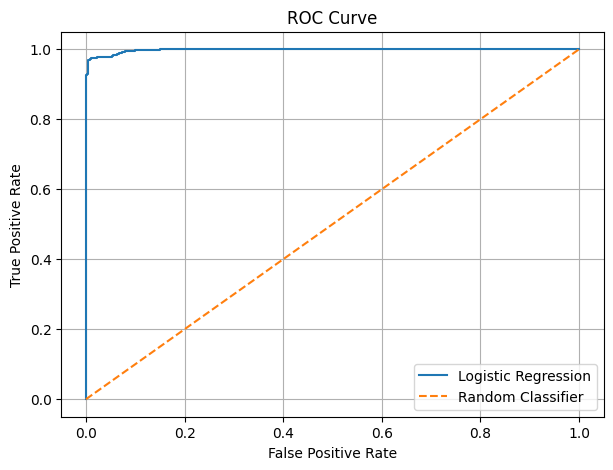

In [ ]:
plt.figure(figsize=(7,5))

plt.plot(fpr,tpr,label=f"Logistic Regression")
plt.plot([0,1],[0,1],linestyle="--",label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1257
           1       0.99      0.97      0.98      1181

    accuracy                           0.98      2438
   macro avg       0.98      0.98      0.98      2438
weighted avg       0.98      0.98      0.98      2438



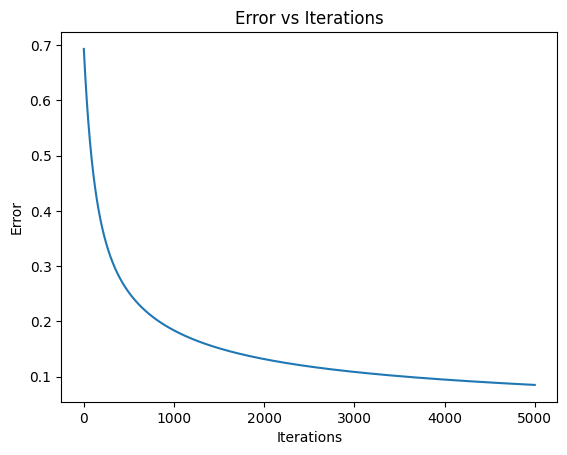

In [ ]:
plt.plot(errors)

plt.xlabel("Iterations")
plt.ylabel("Error")
plt.title("Error vs Iterations")

plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
model= LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred_lib = model.predict(X_test)

In [ ]:
print(classification_report(y_test, y_pred_lib))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1257
           1       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438

